In [1]:
import os
from typing import Dict, Any
from IPython.display import Image, display
from dotenv import load_dotenv
from langchain.agents import create_agent
from langchain_core.tools import tool
from langchain_openai import ChatOpenAI
from langgraph.graph import START, END, StateGraph
from langgraph.graph.message import MessagesState
from langgraph.prebuilt import ToolNode
from langgraph.checkpoint.memory import MemorySaver
from tavily import TavilyClient

In [2]:
load_dotenv()

True

In [3]:
tavily_client = TavilyClient(
    api_key=os.getenv("TAVILY_API_KEY")
)

In [4]:
@tool
def web_search(question:str)->Dict[str, Any]:
    """
    This returns top search results for a given search query
    
    Args:
        question (str): A query to be searched
    
    Returns:
        Dict[str, Any]: A dictionary containing a list of results (url, title, content, score)
    """
    response = tavily_client.search(
        query=question,
        max_results=5,
    )
    return response

In [5]:
message = "Who voiced Count Dracula in Hotel Transylvania 4?"

In [6]:
web_search.invoke(
    {
        "question": message
    }
)

{'query': 'Who voiced Count Dracula in Hotel Transylvania 4?',
 'follow_up_questions': None,
 'answer': None,
 'images': [],
 'results': [{'url': 'https://en.wikipedia.org/wiki/Hotel_Transylvania:_Transformania',
   'title': 'Hotel Transylvania: Transformania - Wikipedia',
   'content': 'Brian Hull as Count "Drac" Dracula, the founder of Hotel Transylvania and Mavis\' father, Johnny\'s father-in-law, Dennis\' maternal grandfather and Ericka\'s husband. In the previous films, he was voiced by Adam Sandler, who was unavailable to return for the fourth installment due to scheduling conflicts.\n Andy Samberg as Jonathan "Johnny" Loughran, Mavis\' husband, Dracula\'s son-in-law, Ericka\'s stepson-in-law and Dennis\' father [...] In April 2021, the film\'s title was revealed as Hotel Transylvania: Transformania, and it was confirmed to be the final entry in the franchise. That same month, Sony announced that Adam Sandler would not reprise his role as Dracula. The role was taken over by Brian

In [7]:
tools = [web_search]

In [8]:
llm = ChatOpenAI(
    model="gpt-4o-mini",
    temperature=0.0,
    base_url="https://openai.vocareum.com/v1",
    api_key=os.getenv("VOCAREUM_API_KEY")
)

## LLM with tools

In [9]:
llm_with_tools = llm.bind_tools(tools)

In [10]:
llm_with_tools.invoke(message)

AIMessage(content='', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 23, 'prompt_tokens': 96, 'total_tokens': 119, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'gpt-4o-mini-2024-07-18', 'system_fingerprint': 'fp_8ee1735ce8', 'id': 'chatcmpl-EmoOy7NwsaA42taocYfQquUHB4M7k', 'service_tier': 'default', 'finish_reason': 'tool_calls', 'logprobs': None, 'normalized_finish_reason': 'tool_call'}, id='lc_run--01a20059-8260-7305-8bf1-1f3080a5b40a-0', tool_calls=[{'name': 'web_search', 'args': {'question': 'who voiced Count Dracula in Hotel Transylvania 4'}, 'id': 'call_LLGnmhcqINk3SIXCToVuefzb', 'type': 'tool_call'}], invalid_tool_calls=[], usage_metadata={'inpu

## Graph from Scratch

In [11]:
def agent(state: MessagesState):
    ai_message = llm_with_tools.invoke(state["messages"])
    return {"messages": ai_message}

In [12]:
def should_call_tool(state: MessagesState):
    last_message = state["messages"][-1]
    if last_message.tool_calls:
        return "tools"

    return END

In [13]:
workflow = StateGraph(MessagesState)

workflow.add_node("agent", agent)
workflow.add_node("tools", ToolNode(tools))

workflow.add_edge(START, "agent")

workflow.add_conditional_edges(
    source="agent", 
    path=should_call_tool, 
    path_map=["tools", END]
)

workflow.add_edge("tools", "agent")


In [14]:
graph = workflow.compile()

In [15]:
type(graph)

langgraph.graph.state.CompiledStateGraph

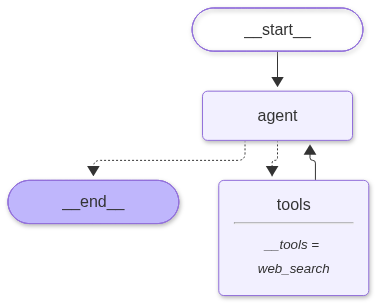

In [16]:
display(
    Image(
        graph.get_graph().draw_mermaid_png()
    )
)

In [17]:
result = graph.invoke(
    input={
        "messages": message
    }
)

In [18]:
for result_message in result["messages"]:
    result_message.pretty_print()

================================ Human Message =================================

Who voiced Count Dracula in Hotel Transylvania 4?
================================== Ai Message ==================================
Tool Calls:
  web_search (call_0hjieBJD4TIDtK3KP7GCq5BB)
 Call ID: call_0hjieBJD4TIDtK3KP7GCq5BB
  Args:
    question: who voiced Count Dracula in Hotel Transylvania 4
================================= Tool Message =================================
Name: web_search

{"query": "who voiced Count Dracula in Hotel Transylvania 4", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://en.wikipedia.org/wiki/Hotel_Transylvania:_Transformania", "title": "Hotel Transylvania: Transformania - Wikipedia", "content": "Brian Hull as Count \"Drac\" Dracula, the founder of Hotel Transylvania and Mavis' father, Johnny's father-in-law, Dennis' maternal grandfather and Ericka's husband. In the previous films, he was voiced by Adam Sandler, who was unavailable to

## Prebuilt

In [19]:
agent = create_agent(
    name="researcher_agent",
    model=llm,
    tools=tools,
)

In [20]:
type(agent)

langgraph.graph.state.CompiledStateGraph

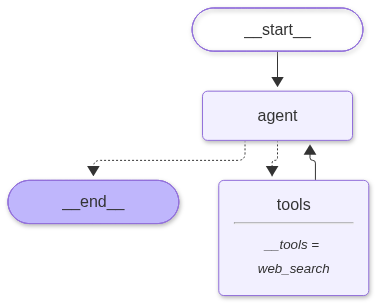

In [21]:
display(
    Image(
        agent.get_graph().draw_mermaid_png()
    )
)

In [22]:
result = agent.invoke(
    input={
        "messages": message
    }
)

In [23]:
for result_message in result["messages"]:
    result_message.pretty_print()

================================== Ai Message ==================================

In "Hotel Transylvania 4," titled "Hotel Transylvania: Transformania," Count Dracula was voiced by Brian Hull. He took over the role from Adam Sandler, who was unable to return due to scheduling conflicts.
================================== Ai Message ==================================
Name: researcher_agent
Tool Calls:
  web_search (call_t1EvBVuVg6GdWRiyzJfKZUEB)
 Call ID: call_t1EvBVuVg6GdWRiyzJfKZUEB
  Args:
    question: Hotel Transylvania 4 Count Dracula voice actor
================================= Tool Message =================================
Name: web_search

{"query": "Hotel Transylvania 4 Count Dracula voice actor", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://screenrant.com/hotel-transylvania-4-voice-cast-character-guide", "title": "Hotel Transylvania 4 Voice Cast: What The Characters Look Like In Real Life", "content": "YouTube personality and impres